<a href="https://colab.research.google.com/github/aunyarit2005-hash/Comparative-Performance-Analysis-of-Image-Classification-Models-for-Malaria-Infected-Red-Blood-Cells/blob/main/Origin_efficientnet_b0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📊 efficientnet-b0 Architecture

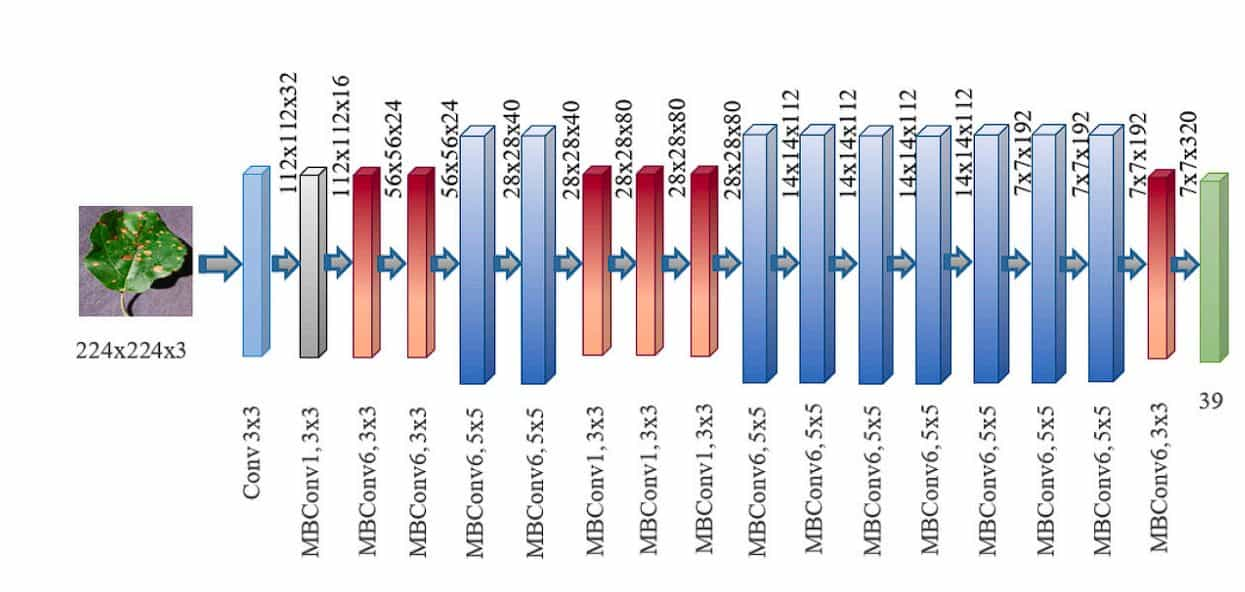

# 📁 แตกไฟล์ zip (แก้ไข file path)

In [ ]:
!unzip /content/Segment_Malariae-20260219T013031Z-1-001.zip -d /content/


Archive:  /content/Segment_Malariae-20260219T013031Z-1-001.zip
  inflating: /content/Segment_Malariae/malaria/val/Screenshot 2026-02-12 225339.png  
  inflating: /content/Segment_Malariae/malaria/val/Screenshot 2026-02-12 225237.png  
  inflating: /content/Segment_Malariae/malaria/val/Screenshot 2026-02-12 225403.png  
  inflating: /content/Segment_Malariae/malaria/val/Screenshot 2026-02-12 225242.png  
  inflating: /content/Segment_Malariae/malaria/val/Screenshot 2026-02-12 225307.png  
  inflating: /content/Segment_Malariae/malaria/val/Screenshot 2026-02-12 225318.png  
  inflating: /content/Segment_Malariae/malaria/val/Screenshot 2026-02-12 225139.png  
  inflating: /content/Segment_Malariae/malaria/val/Screenshot 2026-02-12 225421.png  
  inflating: /content/Segment_Malariae/malaria/val/Screenshot 2026-02-12 225300.png  
  inflating: /content/Segment_Malariae/malaria/val/Screenshot 2026-02-12 225141.png  
  inflating: /content/Segment_Malariae/malaria/val/Screenshot 2026-02-12 2251

# 📁 กำหนด file path สำหรับข้อมูลภาพ Normal และ Malaria
รายละเอียดในโค้ด:
📂 ชุดข้อมูลฝึกสอน (Train): สำหรับให้โมเดลเรียนรู้ลักษณะของเซลล์

🧪 ชุดข้อมูลตรวจสอบ (Validation): สำหรับเช็กความแม่นยำระหว่างเทรน

🔍 ชุดข้อมูลทดสอบ (Test): สำหรับวัดผลหลังเทรนเสร็จว่าแยกแยะได้จริงไหม

In [ ]:
import os
file_path = '/content/Segment_Malariae'

normal_train = os.path.join(file_path, 'normal', 'train')
normal_val = os.path.join(file_path, 'normal', 'val')
normal_test = os.path.join(file_path, 'normal', 'test')

malaria_train = os.path.join(file_path, 'malaria', 'train')
malaria_val = os.path.join(file_path, 'malaria', 'val')
malaria_test = os.path.join(file_path, 'malaria', 'test')

# 🛠️ ฟังก์ชันสำหรับดึง Path ของไฟล์ภาพและกำหนด Label (ป้ายกำกับ)
🔍 การค้นหาไฟล์: ไล่ดูไฟล์ในโฟลเดอร์ที่กำหนดไว้ (Directory)

🖼️ กรองเฉพาะรูปภาพ: เลือกเอาเฉพาะไฟล์นามสกุล .jpg, .jpeg, .png, .gif เท่านั้น

🏷️ ติดป้ายกำกับ: จับคู่รูปภาพกับประเภท (เช่น Normal หรือ Malaria) เพื่อส่งค่ากลับไปเป็น List

In [ ]:
import os
import pandas as pd

# Define a function to get file paths and labels from a directory
def get_filepaths_and_labels(directory, label):
    filepaths = [] # Corrected: initialize as empty list
    labels = []    # Corrected: initialize as empty list
    # Ensure the directory exists before listing its contents
    if os.path.exists(directory):
        for filename in os.listdir(directory):
            # Check for common image file extensions
            if filename.lower().endswith(('.jpg', '.jpeg', '.png', '.gif')):
                filepaths.append(os.path.join(directory, filename))
                labels.append(label)
    else:
        print(f"Warning: Directory not found: {directory}")
    return filepaths, labels




# 📝สร้าง DataFrame สำหรับชุดข้อมูลฝึกสอน (Training Set)
🔗 รวมข้อมูล: เอาลิสต์รายชื่อไฟล์และป้ายกำกับ (Labels) จากทั้งฝั่ง Normal และ Malaria มารวมเข้าด้วยกัน

📝 จัดรูปแบบตาราง: นำข้อมูลทั้งหมดมาสร้างเป็น pd.DataFrame โดยแบ่งเป็นคอลัมน์ filepath (ที่อยู่ไฟล์) และ label (ประเภทของภาพ)

📈 ตรวจสอบจำนวน: แสดงยอดรวมของรูปภาพทั้งหมดที่มีอยู่ในชุด Train เพื่อเช็กความเรียบร้อย

In [ ]:
# --- Create Training DataFrame ---
normal_train_filepaths, normal_train_labels = get_filepaths_and_labels(normal_train, 'normal') # กำหนดชื่อ class
malaria_train_filepaths, malaria_train_labels = get_filepaths_and_labels(malaria_train, 'malaria') # กำหนดชื่อ class

train_filepaths = normal_train_filepaths + malaria_train_filepaths
train_labels = normal_train_labels + malaria_train_labels

# --- Create the training DataFrame ---
train_df = pd.DataFrame({'filepath': train_filepaths, 'label': train_labels})

# Shuffle
train_df = train_df.sample(frac=1).reset_index(drop=True)

print("✅ สร้าง DataFrame สำหรับ Training และ Validation เสร็จแล้ว!")
print(f"จำนวนรูปภาพใน Train DataFrame: {len(train_df)}\n")

✅ สร้าง DataFrame สำหรับ Training และ Validation เสร็จแล้ว!
จำนวนรูปภาพใน Train DataFrame: 1600



# 🔍แสดงตัวอย่างข้อมูลใน Training ใน DataFrame

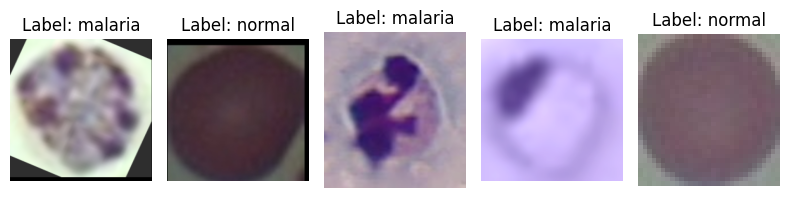

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

# สุ่มเลือกรูปภาพ 5 รูปจาก DataFrame
sample_images = train_df.sample(n=5)

plt.figure(figsize=(8, 8))
for i, row in enumerate(sample_images.itertuples()):
    filepath = row.filepath
    label = row.label

    # โหลดรูปภาพ
    image = Image.open(filepath)

    # แสดงรูปภาพ
    plt.subplot(1, 5, i + 1)
    plt.imshow(image)
    plt.title(f"Label: {label}")
    plt.axis('off')

plt.tight_layout()
plt.show()

# สร้าง DataFrame สำหรับชุดข้อมูลตรวจสอบ (Validation Set)
🔗 รวมข้อมูล: เอาลิสต์รายชื่อไฟล์และป้ายกำกับ (Labels) จากทั้งฝั่ง Normal และ Malaria มารวมเข้าด้วยกัน

📝 จัดรูปแบบตาราง: นำข้อมูลทั้งหมดมาสร้างเป็น pd.DataFrame โดยแบ่งเป็นคอลัมน์ filepath (ที่อยู่ไฟล์) และ label (ประเภทของภาพ)

📈 ตรวจสอบจำนวน: แสดงยอดรวมของรูปภาพทั้งหมดที่มีอยู่ในชุด Validation เพื่อเช็กความเรียบร้อย

In [ ]:

# --- Create Validation DataFrame ---

normal_val_filepaths, normal_val_labels = get_filepaths_and_labels(normal_val, 'normal') # กำหนดชื่อ class
malaria_val_filepaths, malaria_val_labels = get_filepaths_and_labels(malaria_val, 'malaria') # กำหนดชื่อ class

val_filepaths = normal_val_filepaths + malaria_val_filepaths
val_labels = normal_val_labels + malaria_val_labels

# --- Create the validation DataFrame ---

val_df = pd.DataFrame({'filepath': val_filepaths, 'label': val_labels})

# Shuffle
val_df = val_df.sample(frac=1).reset_index(drop=True)


print("✅ สร้าง DataFrame malaria_valid!")
print(f"จำนวนรูปภาพใน Validation DataFrame: {len(val_df)}\n")



✅ สร้าง DataFrame malaria_valid!
จำนวนรูปภาพใน Validation DataFrame: 200



# 🔍แสดงตัวอย่างข้อมูลใน Validation ใน DataFrame

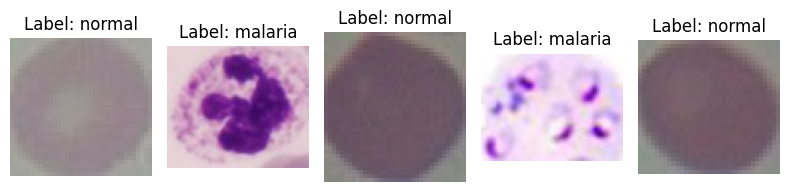

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

# สุ่มเลือกรูปภาพ 5 รูปจาก DataFrame
sample_images = val_df.sample(n=5)

plt.figure(figsize=(8, 8))
for i, row in enumerate(sample_images.itertuples()):
    filepath = row.filepath
    label = row.label

    # โหลดรูปภาพ
    image = Image.open(filepath)

    # แสดงรูปภาพ
    plt.subplot(1, 5, i + 1)
    plt.imshow(image)
    plt.title(f"Label: {label}")
    plt.axis('off')

plt.tight_layout()
plt.show()

# สร้าง DataFrame สำหรับชุดข้อมูลทดสอบ (Testing Set)
🔗 รวมข้อมูล: เอาลิสต์รายชื่อไฟล์และป้ายกำกับ (Labels) จากทั้งฝั่ง Normal และ Malaria มารวมเข้าด้วยกัน

📝 จัดรูปแบบตาราง: นำข้อมูลทั้งหมดมาสร้างเป็น pd.DataFrame โดยแบ่งเป็นคอลัมน์ filepath (ที่อยู่ไฟล์) และ label (ประเภทของภาพ)

📈 ตรวจสอบจำนวน: แสดงยอดรวมของรูปภาพทั้งหมดที่มีอยู่ในชุด Testing เพื่อเช็กความเรียบร้อย

In [ ]:
# --- Create the Testing DataFrame ---

normal_test_filepaths, normal_test_labels = get_filepaths_and_labels(normal_test, 'normal') # กำหนดชื่อ class
malaria_test_filepaths, malaria_test_labels = get_filepaths_and_labels(malaria_test, 'malaria') # กำหนดชื่อ class

test_filepaths = normal_test_filepaths + malaria_test_filepaths
test_labels = normal_test_labels + malaria_test_labels

# Create the test DataFrame
test_df = pd.DataFrame({'filepath': test_filepaths, 'label': test_labels})



print(f"✅ สร้าง DataFrame สำหรับ Test เสร็จแล้ว")
print(f"จำนวนรูปภาพใน Test DataFrame: {len(test_df)}")

✅ สร้าง DataFrame สำหรับ Test เสร็จแล้ว
จำนวนรูปภาพใน Test DataFrame: 200


# 🔍แสดงตัวอย่างข้อมูลใน Testing ใน DataFrame

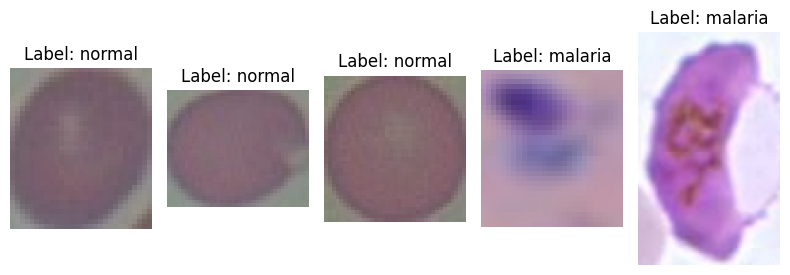

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

# สุ่มเลือกรูปภาพ 5 รูปจาก DataFrame
sample_images = test_df.sample(n=5)

plt.figure(figsize=(8, 8))
for i, row in enumerate(sample_images.itertuples()):
    filepath = row.filepath
    label = row.label

    # โหลดรูปภาพ
    image = Image.open(filepath)

    # แสดงรูปภาพ
    plt.subplot(1, 5, i + 1)
    plt.imshow(image)
    plt.title(f"Label: {label}")
    plt.axis('off')

plt.tight_layout()
plt.show()

#

# นำเข้า EfficientNetB0 และ ImageDataGenerator

In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping


#🧠 สร้างและตั้งค่าโมเดล EfficientNet-B0

In [ ]:

########################### Parameters ที่สามารถปรับแต่งได้ ####################################

NUM_CLASSES = 2 # 'normal' and 'malaria'

IMG_SIZE = 224 # ขนาดรูปภาพ

learning_rate = 0.0001 # Learning rate สามารถเป็น 0.1, 0.01, 0.0001, 0.00001 (ค่ายิ่งน้อยต้องใช้เวลาการฝึกโมเดลมากขึ้น)

BATCH_SIZE = 32

base_model = EfficientNetB0(
    weights='imagenet',
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)

)


##########################################################################################


base_model.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation='relu')(x)
predictions = Dense(NUM_CLASSES, activation='softmax')(x)


model = Model(inputs=base_model.input, outputs=predictions)

model.compile(
    optimizer=Adam(learning_rate),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ input_layer[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 224, 224,  │          7 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 224, 224,  │          0 │ normalization[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 225, 225,  │          0 │ rescaling_1[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 112, 112,  │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 112, 112,  │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 112, 112,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 112, 112,  │          0 │ block1a_activati… │
│ (Multiply)          │ 32)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 112, 112,  │        512 │ block1a_se_excit

 Total params: 4,378,021 (16.70 MB)

 Trainable params: 328,450 (1.25 MB)

 Non-trainable params: 4,049,571 (15.45 MB)


# 📠สร้าง Data Generator สำหรับชุดฝึกสอน (Training set) และชุดตรวจสอบ (Validation Set)

In [ ]:

# Data augmentation and preprocessing
train_datagen = ImageDataGenerator(
    rescale=1./255,
    shear_range=0.2,             # Shear transformations
    zoom_range=0.2,              # Zoom transformations
    horizontal_flip=True         # Horizontal flip
)

val_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

# Create data generators from DataFrames

# Training Generator
train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col='filepath',
    y_col='label',
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    # subset='training' # Not using validation split in ImageDataGenerator directly as we have separate DFs
)

# Validation Generator
validation_generator = val_datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col='filepath',
    y_col='label',
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle = False
)


Found 1600 validated image filenames belonging to 2 classes.
Found 200 validated image filenames belonging to 2 classes.


# การตั้งค่า Early Stopping

In [ ]:
# หยุดการเทรนเมื่อ Validation Loss ไม่ลดลงอีกแล้ว
callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
]

# เริ่มการฝึกสอนโมเดล (Model Training)

In [ ]:
################### Parameter ที่สามารถปรับแต่งได้ ##############################

EPOCHS = 10 # จำนวนรอบในการฝึกฝน

############################################################

history = model.fit(train_generator,
    epochs=EPOCHS,
    validation_data=validation_generator,
    callbacks=callbacks
)

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 159s 3s/step - accuracy: 0.5108 - loss: 0.6999 - val_accuracy: 0.5000 - val_loss: 0.7032
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 197s 3s/step - accuracy: 0.4945 - loss: 0.6995 - val_accuracy: 0.5000 - val_loss: 0.6942
Epoch 3/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 143s 3s/step - accuracy: 0.4833 - loss: 0.6991 - val_accuracy: 0.5000 - val_loss: 0.7025
Epoch 4/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 142s 3s/step - accuracy: 0.4785 - loss: 0.7033 - val_accuracy: 0.5000 - val_loss: 0.6932
Epoch 5/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 148s 3s/step - accuracy: 0.5144 - loss: 0.6938 - val_accuracy: 0.5000 - val_loss: 0.6940
Epoch 6/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 142s 3s/step - accuracy: 0.5192 - loss: 0.6929 - val_accuracy: 0.5000 - val_loss: 0.6992
Epoch 7/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 142s 3s/step - accuracy: 0.5025 - loss: 0.6937 - val_accuracy: 0.5000 - val_loss: 0.6942
Epoch 8/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 142s 3s/step - accuracy: 0.5032 - loss: 0.6990 - val_accuracy: 0.5000 - v

# กราฟแสดงผลเปรียบเทียบ Accuracy และ Loss ของ Training set


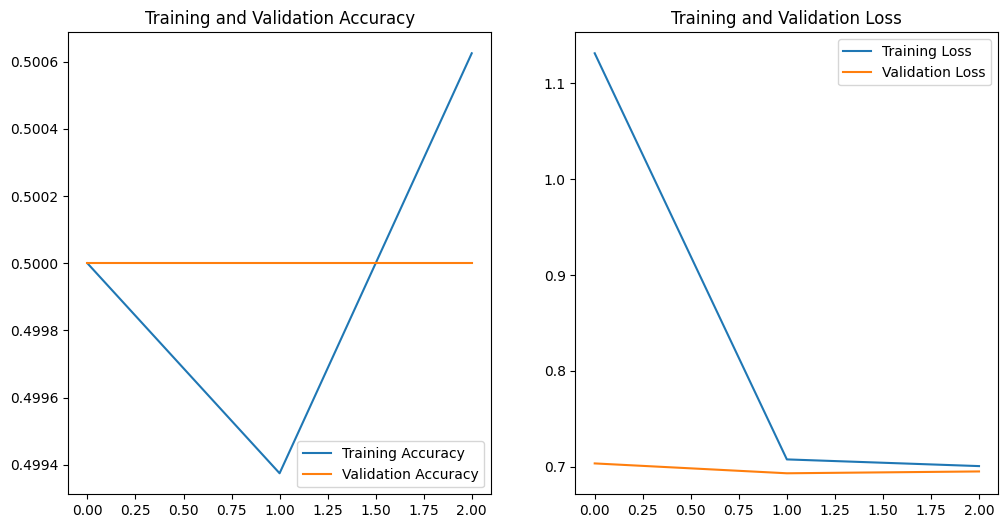

In [ ]:
import matplotlib.pyplot as plt

def plot_history(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']

    epochs_range = range(len(acc))

    plt.figure(figsize=(12, 6))

    # กราฟ Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='Training Accuracy')
    plt.plot(epochs_range, val_acc, label='Validation Accuracy')
    plt.legend(loc='lower right')
    plt.title('Training and Validation Accuracy')

    # กราฟ Loss
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='Training Loss')
    plt.plot(epochs_range, val_loss, label='Validation Loss')
    plt.legend(loc='upper right')
    plt.title('Training and Validation Loss')

    plt.show()


plot_history(history)

# 📝 ทดสอบความแม่นยำบนชุดข้อมูล Validation

In [ ]:
print("กำลังตรวจข้อสอบ")
val_loss, val_acc = model.evaluate(validation_generator)

print(f"Loss (ค่าความผิดพลาด): {val_loss:.4f}")
print(f"Accuracy (ความแม่น): {val_acc:.4f}")

กำลังตรวจข้อสอบ
4/4 ━━━━━━━━━━━━━━━━━━━━ 16s 3s/step - accuracy: 0.5339 - loss: 0.6925
Loss (ค่าความผิดพลาด): 0.6931
Accuracy (ความแม่น): 0.5000


4/4 ━━━━━━━━━━━━━━━━━━━━ 14s 3s/step


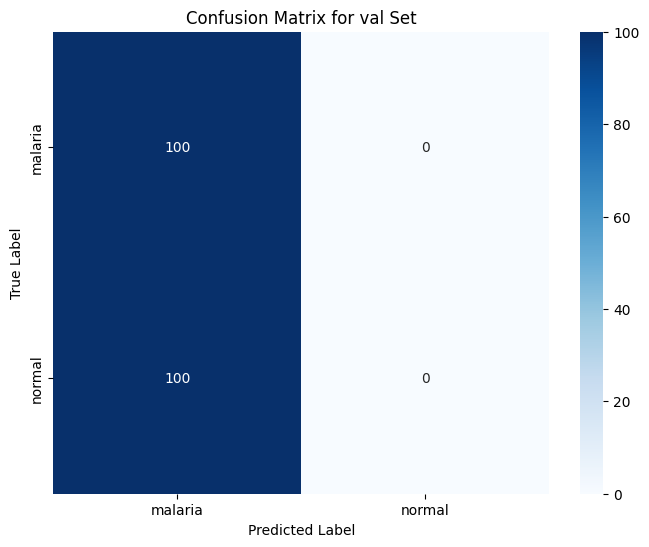

✅ สร้าง Confusion Matrix เสร็จแล้ว!


In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import seaborn as sns

validation_generator.reset()
predictions = model.predict(validation_generator)
predicted_classes = np.argmax(predictions, axis=1)
true_classes = validation_generator.classes
class_names = list(validation_generator.class_indices.keys())
cm = confusion_matrix(true_classes, predicted_classes)


plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix for val Set')
plt.show()

print("✅ สร้าง Confusion Matrix เสร็จแล้ว!")

# 🏁 ขั้นตอนการทดสอบโมเดล (Model Evaluation)

#📠สร้าง Data Generator สำหรับ ชุดข้อมูลทดสอบ (Testing Set)

In [ ]:
# Testing Generator
test_generator = test_datagen.flow_from_dataframe(
    dataframe=test_df,
    x_col='filepath',
    y_col='label',
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False # Do not shuffle test data to maintain order for evaluation
)


Found 200 validated image filenames belonging to 2 classes.


# เริ่มการทดสอบโมเดล (Model Testing)

In [ ]:
print("Evaluating model on test data...")
loss, accuracy = model.evaluate(test_generator)
print(f"Test Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy:.4f}")

Evaluating model on test data...


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


4/4 ━━━━━━━━━━━━━━━━━━━━ 15s 3s/step - accuracy: 0.3396 - loss: 0.6961
Test Loss: 0.6930
Test Accuracy: 0.5000


# นำเข้า Library สำหรับประเมินผลและสร้าง Confusion Matrix ของ Testing set

4/4 ━━━━━━━━━━━━━━━━━━━━ 20s 4s/step


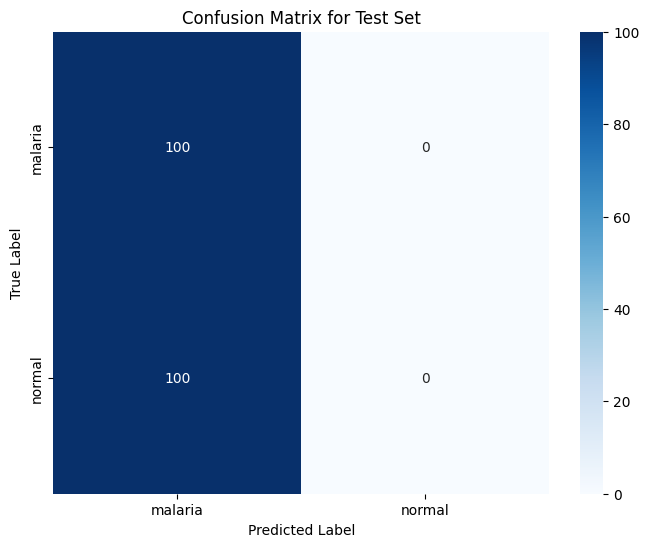

✅ สร้าง Confusion Matrix เสร็จแล้ว!


In [ ]:


# --- 1. Get true labels and predictions ---

# Reset the test_generator to ensure predictions start from the beginning
test_generator.reset()

# Get predictions from the model
predictions = model.predict(test_generator)

# Get predicted class labels (index of the highest probability)
predicted_classes = np.argmax(predictions, axis=1)

# Get true class labels
true_classes = test_generator.classes

# Get class names from the generator
class_names = list(test_generator.class_indices.keys())

# --- 2. Calculate the Confusion Matrix ---
cm = confusion_matrix(true_classes, predicted_classes)

# --- 3. Plot the Confusion Matrix ---
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix for Test Set')
plt.show()

print("✅ สร้าง Confusion Matrix เสร็จแล้ว!")

In [ ]:
import pandas as pd
from sklearn.metrics import classification_report

report = classification_report(
    true_classes,
    predicted_classes,
    target_names=class_names,
    output_dict=True
)

df = pd.DataFrame(report).transpose()
# df = df.drop(["macro avg", "weighted avg"], errors="ignore")
# ปัดทศนิยมให้ดูสะอาด
df = df.round(3)

# ใส่สีไล่ตามค่า
styled = (
    df.style
    .background_gradient(cmap="YlGnBu")  # โทนฟ้าเขียว
    .format(precision=3)
)

styled

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


,precision,recall,f1-score,support
malaria,0.500,1.000,0.667,100.000
normal,0.000,0.000,0.000,100.000
accuracy,0.500,0.500,0.500,0.500
macro avg,0.250,0.500,0.333,200.000
weighted avg,0.250,0.500,0.333,200.000


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 153ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 156ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 144ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step


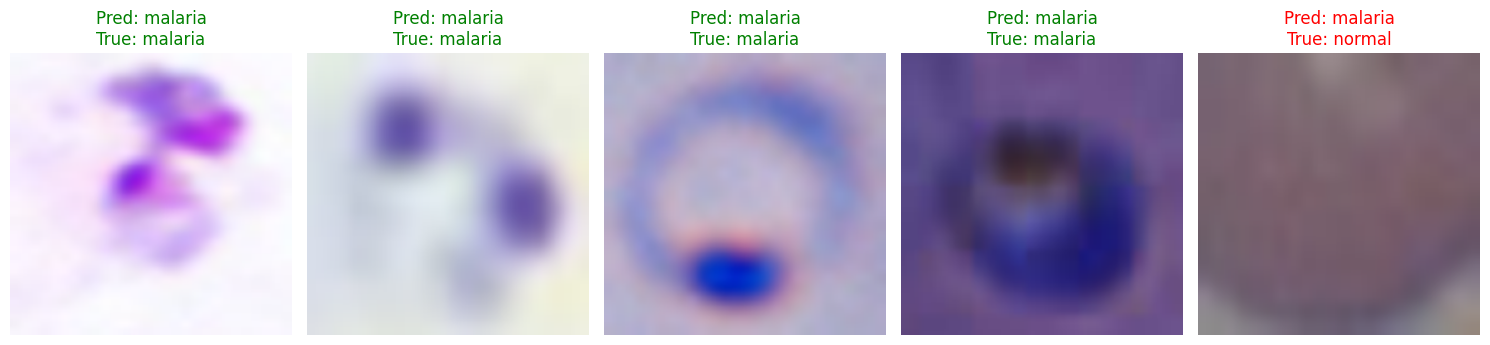

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Data Generator สำหรับการ preprocess รูปภาพก่อนส่งเข้าโมเดล (ไม่ต้อง Augmentation)
test_predict_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input # แปลงค่าสีให้เหมาะกับ MobileNet
)

# สุ่มเลือกรูปภาพ 5 รูปจาก DataFrame
sample_images_df = test_df.sample(n=5) # ใช้ random_state เพื่อให้ผลลัพธ์ซ้ำเดิมได้

plt.figure(figsize=(15, 6))
for i, row in enumerate(sample_images_df.itertuples()):
    filepath = row.filepath
    true_label = row.label

    # โหลดรูปภาพและปรับขนาด
    img = Image.open(filepath).resize((224, 224))
    # === FIX: Convert image to RGB to ensure 3 channels ===
    img = img.convert('RGB')
    # ==================================================
    img_array = np.array(img) # แปลงเป็น numpy array
    img_array = np.expand_dims(img_array, axis=0) # เพิ่มมิติ batch
    img_array = preprocess_input(img_array) # Preprocess ด้วยฟังก์ชันของ MobileNetV2

    # ทำนายผล
    prediction = model.predict(img_array)
    predicted_class_index = np.argmax(prediction, axis=1)[0]
    # ดึงชื่อคลาสจาก class_names ที่สร้างไว้ก่อนหน้านี้
    predicted_label = class_names[predicted_class_index]

    # แสดงรูปภาพ
    plt.subplot(1, 5, i + 1)
    plt.imshow(img) # แสดงรูปภาพก่อน preprocess สำหรับการมองเห็น
    plt.title(f"Pred: {predicted_label}\nTrue: {true_label}", color=('green' if predicted_label == true_label else 'red'))
    plt.axis('off')

plt.tight_layout()
plt.show()


# 📊 ทดสอบโมเดล

In [ ]:
from google.colab import files
from tensorflow.keras.preprocessing import image

uploaded = files.upload()

for filename in uploaded.keys():
    img = image.load_img(filename, target_size=(224, 224))
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    img_array = preprocess_input(img_array)

    predictions = model.predict(img_array)
    class_names = list(train_generator.class_indices.keys())

    idx = np.argmax(predictions[0])
    label = class_names[idx]
    conf = predictions[0][idx] * 100

    plt.imshow(image.load_img(filename))
    plt.title(f"Predicted: {label}\nConfidence: {conf:.2f}%")
    plt.axis('off')
    plt.show()

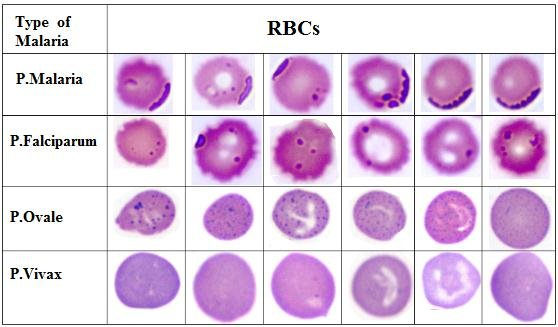